# Grad-CAM for anomaly detection – processes A and B

**Why a neural network here?** Grad-CAM explains a *convolutional neural network*: it uses the gradients of the network's output with respect to its last convolutional feature maps to show **which part of the input drives the output**. The detectors in `anomaly_detection.ipynb` (robust score, Isolation Forest) are not neural networks, so Grad-CAM cannot be applied to them. Here we therefore train a small one-class neural detector and explain it with Grad-CAM.

**Detector:** a 1D convolutional **autoencoder** trained **only on accepted batches**. It learns to reproduce normal trajectories; a batch it reproduces badly is anomalous. **Anomaly score = mean squared reconstruction error** of the batch.

**Grad-CAM over time:** target = the batch's anomaly score; layer = last encoder convolution. The gradient of the score with respect to each feature map, averaged over time, gives that map's weight; the weighted sum of the maps (negative parts set to 0) is a heatmap over time, scaled to 0–1. **High values = the moments in the batch that make the network call it anomalous.**

**Threshold:** 95th percentile of accepted scores, computed **out-of-fold** (5-fold: each accepted batch is scored by an autoencoder trained without it). Rejected batches are scored by the autoencoder trained on all accepted batches.

**Second explanation – reconstruction-error map:** for an autoencoder there is a more direct answer to *where*: the reconstruction error at each time point (averaged over channels). We show it next to Grad-CAM and check both against the known fault.

**Sanity check:** in process B we know the answer – every rejected batch has an aeration drop at t = 500–1250 (EDA). If Grad-CAM works, the rejected batches should light up in that window.

## 0. Setup & data
Every batch becomes a fixed-size array (variables × time). Process A: batches have different lengths, so each is resampled to 256 points on normalised time (0 = start, 1 = end). Process B: all batches have 5001 timesteps; they are averaged in blocks of 10 timesteps → 500 points. Constant variables are dropped.

**Two channels per variable:** (1) **level** – the value standardised with the mean and std of the accepted batches; (2) **shape** – the value minus the batch's own median, divided by how much accepted batches move around their own median. Without the shape channel the network is blind to the process-B fault: batches differ in their `aeration_rate` *level* (4.8–8.1) about as much as the drop itself, so a 2-unit dip in 1 of 16 variables hardly changes the error (a first version with level channels only detected 0 of 5 rejected B batches).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
                     "axes.titleweight":"bold","axes.titlesize":10,"axes.labelsize":9,"legend.frameon":False,"legend.fontsize":9,"axes.formatter.useoffset":False})
ACC,REJ,TEST,INK,WIN_COL="#8a8f98","#d62728","#2a78d6","#333333","#f0e442"
CAM_CMAP="Purples"                                       # one-hue sequential: light = unimportant, dark = drives the anomaly score
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(4)

ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal")
    lab=pd.read_csv(b/"calibration data/calibration_labels.csv").set_index("batch_id").label
    return cal,lab

def to_array(df,p,V):
    """batches -> array (n_batches, n_variables, n_time) and the time axis"""
    ids=list(df.batch_id.unique()); out=[]
    for b,x in df.groupby("batch_id",sort=False):
        X=x[V].values
        if p=="A":                                      # resample to 256 points on normalised time
            tn=np.linspace(0,1,len(X)); g=np.linspace(0,1,256)
            out.append(np.stack([np.interp(g,tn,X[:,j]) for j in range(len(V))]))
        else:                                           # B: 5000 timesteps -> 500 blocks of 10
            out.append(X[:5000].reshape(500,10,len(V)).mean(1).T)
    t=np.linspace(0,1,256) if p=="A" else np.arange(500)*10+5
    return ids,np.array(out,dtype=np.float32),t

D={}
for p in ("A","B"):
    cal,lab=load(p)
    V=[c for c in cal.columns if c!="batch_id" and cal[c].nunique()>1]
    ids,X,t=to_array(cal,p,V); y=lab.reindex(ids).values; acc=y=="accepted"
    mu=X[acc].mean(axis=(0,2),keepdims=True); sd=X[acc].std(axis=(0,2),keepdims=True)+1e-8
    level=(X-mu)/sd                                                    # channel set 1: level
    cen=X-np.median(X,axis=2,keepdims=True)                            # channel set 2: shape (deviation from the batch's own median)
    sc=np.maximum(cen[acc].std(axis=(0,2),keepdims=True),1e-3*sd)+1e-12
    shape=cen/sc
    D[p]=dict(ids=ids,X=np.concatenate([level,shape],1).astype(np.float32),Xraw=X,t=t,V=V,y=y,acc=acc)
    print(f"process {p}: {len(ids)} batches ({acc.sum()} accepted), {len(V)} variables -> {2*len(V)} input channels (level + shape), {X.shape[2]} time points per batch")

process A: 161 batches (121 accepted), 11 variables -> 22 input channels (level + shape), 256 time points per batch
process B: 40 batches (35 accepted), 16 variables -> 32 input channels (level + shape), 500 time points per batch


## 1. The autoencoder and Grad-CAM
Encoder: three 1D convolutions (each halves the time resolution); decoder: three transposed convolutions back to the input size. Grad-CAM is taken on the **output of the last encoder convolution** (64 feature maps, 1/8 of the time resolution), then stretched back to the full time axis. `explain()` also returns HiResCAM (a Grad-CAM variant that keeps the gradient at every time point instead of averaging it) and the reconstruction-error map, each scaled to 0–1 within the batch.

In [2]:
class AE(nn.Module):
    def __init__(s,c):
        super().__init__()
        s.enc=nn.Sequential(nn.Conv1d(c,32,7,2,3),nn.ReLU(),nn.Conv1d(32,64,5,2,2),nn.ReLU(),nn.Conv1d(64,64,5,2,2),nn.ReLU())
        s.dec=nn.Sequential(nn.ConvTranspose1d(64,64,4,2,1),nn.ReLU(),nn.ConvTranspose1d(64,32,4,2,1),nn.ReLU(),nn.ConvTranspose1d(32,c,4,2,1))
    def forward(s,x):
        z=s.enc(x); r=s.dec(z); return r[...,:x.shape[-1]],z

def train(X,epochs=400,seed=0):
    torch.manual_seed(seed); m=AE(X.shape[1]); opt=torch.optim.Adam(m.parameters(),1e-3); Xt=torch.tensor(X)
    for _ in range(epochs):
        opt.zero_grad(); r,_=m(Xt); loss=((r-Xt)**2).mean(); loss.backward(); opt.step()
    return m.eval()

def score(m,X):
    with torch.no_grad(): r,_=m(torch.tensor(X))
    return ((r-torch.tensor(X))**2).mean(dim=(1,2)).numpy()

def explain(m,x):
    """for one batch: Grad-CAM, HiResCAM and reconstruction-error map over time (each scaled 0-1), + per-variable error"""
    xt=torch.tensor(x[None]); r,z=m(xt); z.retain_grad()
    err=(r-xt)**2; err.mean().backward()
    g,A=z.grad[0],z[0]
    up=lambda c: np.interp(np.linspace(0,1,x.shape[-1]),np.linspace(0,1,len(c)),c)
    norm=lambda c: c/c.max() if c.max()>0 else c
    gradcam=norm(up(torch.relu((g.mean(1,keepdim=True)*A).sum(0)).detach().numpy()))   # Grad-CAM: time-averaged gradient as map weight
    hires=norm(up(torch.relu((g*A).sum(0)).detach().numpy()))                          # HiResCAM: gradient x activation at each time point
    emap=norm(err[0].mean(0).detach().numpy())                                         # reconstruction error at each time point
    e=err[0].mean(1).detach().numpy(); nv=len(e)//2
    return dict(gradcam=gradcam,hires=hires,error=emap,var_err=e[:nv]+e[nv:])          # per-variable error = level + shape channel

## 2. Detection performance (to check the detector is worth explaining)
Accepted batches: out-of-fold scores (5-fold, autoencoder trained without them). Rejected batches: autoencoder trained on all accepted batches. Threshold = 95th percentile of the accepted out-of-fold scores.

process A: false alarms on accepted 6/121 (5.0 %) | rejected detected 15/40 (37.5 %) | threshold 0.582


process B: false alarms on accepted 2/35 (5.7 %) | rejected detected 5/5 (100.0 %) | threshold 0.0879


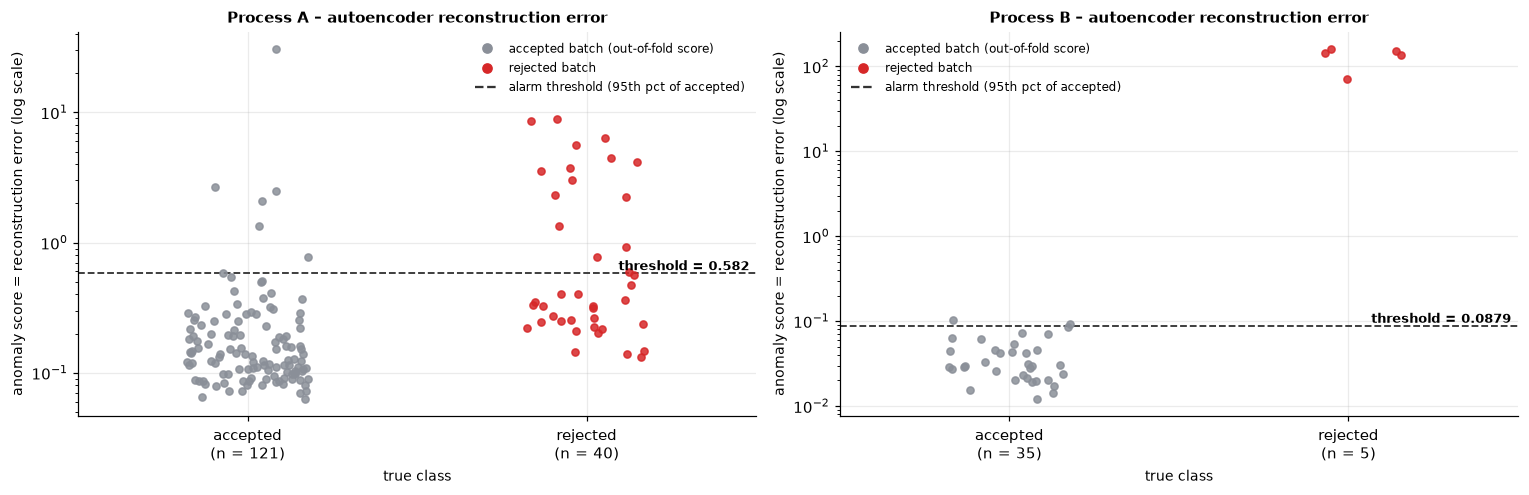

In [3]:
RES={}
for p in ("A","B"):
    d=D[p]; X,acc=d["X"],d["acc"]; ia=np.where(acc)[0]; ir=np.where(~acc)[0]
    s=np.zeros(len(X))
    for k,(tr,te) in enumerate(KFold(5,shuffle=True,random_state=0).split(ia)):
        s[ia[te]]=score(train(X[ia[tr]],seed=k),X[ia[te]])
    m_all=train(X[ia],seed=99); s[ir]=score(m_all,X[ir])
    thr=np.percentile(s[ia],95); flag=s>thr
    cm=confusion_matrix(~acc,flag,labels=[False,True])
    RES[p]=dict(score=s,thr=thr,flag=flag,model=m_all,cm=cm)
    print(f"process {p}: false alarms on accepted {cm[0,1]}/{cm[0].sum()} ({100*cm[0,1]/cm[0].sum():.1f} %) | "
          f"rejected detected {cm[1,1]}/{cm[1].sum()} ({100*cm[1,1]/cm[1].sum():.1f} %) | threshold {thr:.3g}")

fig,axs=plt.subplots(1,2,figsize=(14,4.6))
for ax,p in zip(axs,("A","B")):
    r=RES[p]; acc=D[p]["acc"]; rng=np.random.default_rng(0)
    for k,x0,c in ((acc,0,ACC),(~acc,1,REJ)):
        ax.scatter(x0+rng.uniform(-.18,.18,k.sum()),r["score"][k],color=c,s=22,alpha=.85,zorder=3)
    ax.axhline(r["thr"],color=INK,ls="--",lw=1.2); ax.text(1.48,r["thr"],f"threshold = {r['thr']:.3g}",ha="right",va="bottom",fontsize=8.5,fontweight="bold")
    ax.set_yscale("log"); ax.set_xticks([0,1],[f"accepted\n(n = {acc.sum()})",f"rejected\n(n = {(~acc).sum()})"]); ax.set_xlim(-.5,1.5)
    ax.set(title=f"Process {p} – autoencoder reconstruction error",xlabel="true class",ylabel="anomaly score = reconstruction error (log scale)")
    ax.legend(handles=[Line2D([],[],marker="o",ls="",color=ACC,label="accepted batch (out-of-fold score)"),Line2D([],[],marker="o",ls="",color=REJ,label="rejected batch"),
                       Line2D([],[],color=INK,ls="--",label="alarm threshold (95th pct of accepted)")],loc="best",fontsize=8)
plt.tight_layout(); plt.show()

## 3. Process B – Grad-CAM vs reconstruction-error map, every rejected batch
Each block shows one batch: **top** – its `aeration_rate` (red = rejected, blue = a typical accepted batch for reference) against all accepted batches (grey), with the known aeration-drop window shaded yellow; **middle strip** – Grad-CAM over time; **bottom strip** – reconstruction-error map over time (darker = more important, scaled 0–1 within the batch). A faithful explanation should be dark inside the yellow window.

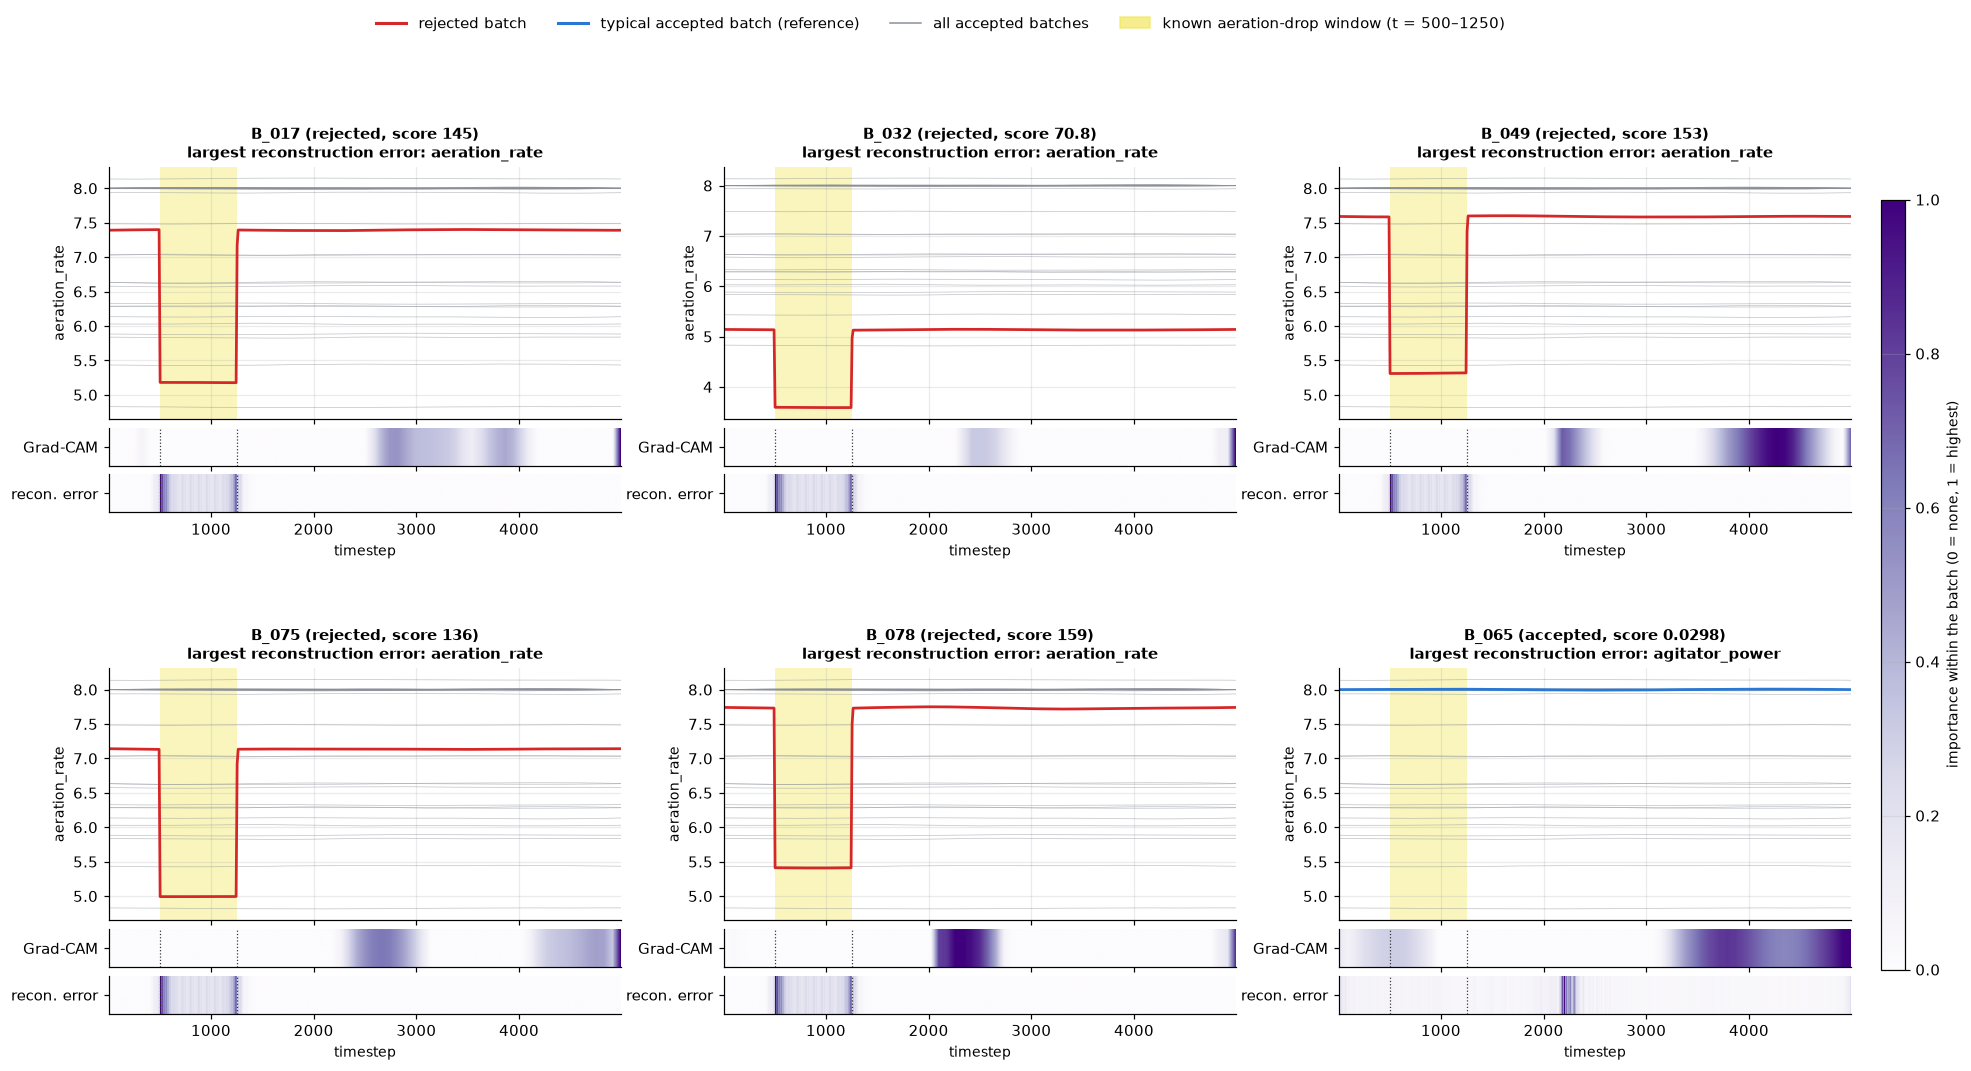

In [4]:
from matplotlib.gridspec import GridSpecFromSubplotSpec
def explain_block(fig,spec,p,i,var=None,window=None):
    d=D[p]; r=RES[p]; ex=explain(r["model"],d["X"][i]); t=d["t"]
    v=var or d["V"][int(np.argmax(ex["var_err"]))]; j=d["V"].index(v)
    gs=GridSpecFromSubplotSpec(3,1,subplot_spec=spec,height_ratios=[4,.6,.6],hspace=.08)
    ax=fig.add_subplot(gs[0]); a1=fig.add_subplot(gs[1],sharex=ax); a2=fig.add_subplot(gs[2],sharex=ax)
    if window: ax.axvspan(*window,color=WIN_COL,alpha=.35,lw=0)
    for k in np.where(d["acc"])[0]: ax.plot(t,d["Xraw"][k,j],color=ACC,lw=.5,alpha=.5)
    ax.plot(t,d["Xraw"][i,j],color=REJ if d["y"][i]=="rejected" else TEST,lw=1.8)
    ax.set_title(f"{d['ids'][i]} ({d['y'][i]}, score {r['score'][i]:.3g})\nlargest reconstruction error: {d['V'][int(np.argmax(ex['var_err']))]}")
    ax.set_ylabel(v); plt.setp(ax.get_xticklabels(),visible=False)
    for a_,key,lab in ((a1,"gradcam","Grad-CAM"),(a2,"error","recon. error")):
        a_.imshow(ex[key][None,:],aspect="auto",cmap=CAM_CMAP,vmin=0,vmax=1,extent=(t[0],t[-1],0,1)); a_.set_yticks([.5],[lab]); a_.grid(False)
        if window: a_.axvline(window[0],color=INK,lw=.8,ls=":"); a_.axvline(window[1],color=INK,lw=.8,ls=":")
    plt.setp(a1.get_xticklabels(),visible=False); a2.set_xlabel("timestep" if p=="B" else "normalised time (0 = start, 1 = end)")
    return ex

def add_colorbar_and_legend(fig,window_label=None):
    cax=fig.add_axes([.945,.15,.012,.7]); fig.colorbar(plt.cm.ScalarMappable(cmap=CAM_CMAP,norm=plt.Normalize(0,1)),cax=cax,label="importance within the batch (0 = none, 1 = highest)")
    h=[Line2D([],[],color=REJ,lw=2,label="rejected batch"),Line2D([],[],color=TEST,lw=2,label="typical accepted batch (reference)"),Line2D([],[],color=ACC,lw=1,label="all accepted batches")]
    if window_label: h.append(Patch(color=WIN_COL,alpha=.6,label=window_label))
    fig.legend(handles=h,loc="lower center",bbox_to_anchor=(.47,.99),ncol=len(h),frameon=False,fontsize=10)

d=D["B"]; rej_i=list(np.where(~d["acc"])[0])
typ=int(np.argsort(RES["B"]["score"][d["acc"]])[d["acc"].sum()//2]); acc_i=int(np.where(d["acc"])[0][typ])   # a typical accepted batch
fig=plt.figure(figsize=(18,10)); outer=fig.add_gridspec(2,3,left=.05,right=.93,hspace=.45,wspace=.2)
for k,i in enumerate(rej_i+[acc_i]): explain_block(fig,outer[k//3,k%3],"B",i,var="aeration_rate",window=(500,1250))
add_colorbar_and_legend(fig,"known aeration-drop window (t = 500–1250)"); plt.show()

### 3.1 Sanity check: does each explanation point at the known fault? (process B)
For every batch, the share of the explanation's total weight that falls inside t = 500–1250. The window covers 15 % of the batch, so **≈ 15 % = no better than chance**; a faithful explanation of the rejected batches should be far above that.

explanation,rejected batches: mean share in window,accepted batches: mean share in window
Grad-CAM,0 %,8 %
HiResCAM (Grad-CAM variant),17 %,15 %
reconstruction-error map,88 %,10 %


chance level = 15 % (the window's share of the batch)


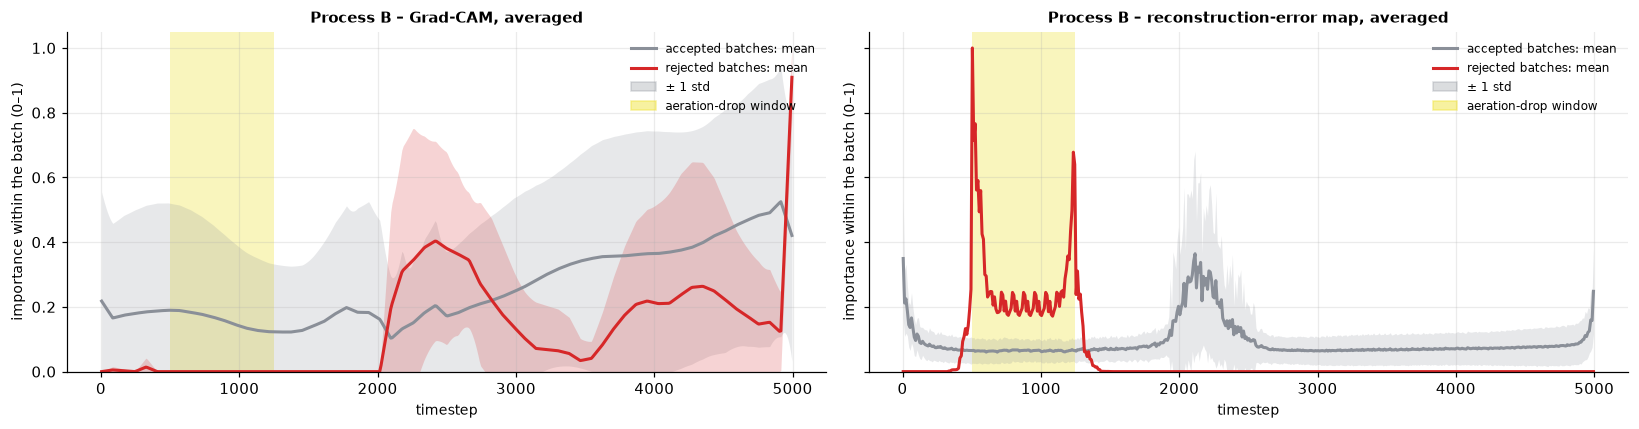

In [5]:
d=D["B"]; inside=(d["t"]>=500)&(d["t"]<=1250)
EX=[explain(RES["B"]["model"],d["X"][i]) for i in range(len(d["ids"]))]
share=lambda c: c[inside].sum()/c.sum() if c.sum()>0 else np.nan
rows=[]
for key,lab in (("gradcam","Grad-CAM"),("hires","HiResCAM (Grad-CAM variant)"),("error","reconstruction-error map")):
    sh=np.array([share(e[key]) for e in EX])
    rows.append({"explanation":lab,"rejected batches: mean share in window":f"{100*np.nanmean(sh[~d['acc']]):.0f} %","accepted batches: mean share in window":f"{100*np.nanmean(sh[d['acc']]):.0f} %"})
display(pd.DataFrame(rows).style.hide(axis="index"))
print(f"chance level = {100*inside.mean():.0f} % (the window's share of the batch)")

fig,axs=plt.subplots(1,2,figsize=(15,4),sharey=True)
for ax,(key,lab) in zip(axs,(("gradcam","Grad-CAM"),("error","reconstruction-error map"))):
    ax.axvspan(500,1250,color=WIN_COL,alpha=.35,lw=0)
    for k,c,l in ((d["acc"],ACC,"accepted batches"),(~d["acc"],REJ,"rejected batches")):
        M=np.array([EX[i][key] for i in np.where(k)[0]]); m=M.mean(0); sdv=M.std(0)
        ax.plot(d["t"],m,color=c,lw=2,label=f"{l}: mean"); ax.fill_between(d["t"],np.clip(m-sdv,0,1),np.clip(m+sdv,0,1),color=c,alpha=.2,lw=0)
    ax.set(title=f"Process B – {lab}, averaged",xlabel="timestep",ylabel="importance within the batch (0–1)",ylim=(0,1.05))
    ax.legend(handles=ax.get_legend_handles_labels()[0]+[Patch(color=ACC,alpha=.3,label="± 1 std"),Patch(color=WIN_COL,alpha=.5,label="aeration-drop window")],loc="upper right",fontsize=8)
plt.tight_layout(); plt.show()

## 4. Process A – the most anomalous rejected batches
No single known fault window here – the EDA found level offsets and extra `temperature_1` noise. Each block shows the variable with the **largest reconstruction error** for that batch, with Grad-CAM and the reconstruction-error map below. Shown: the 5 rejected batches with the highest anomaly score, and a typical accepted batch for reference.

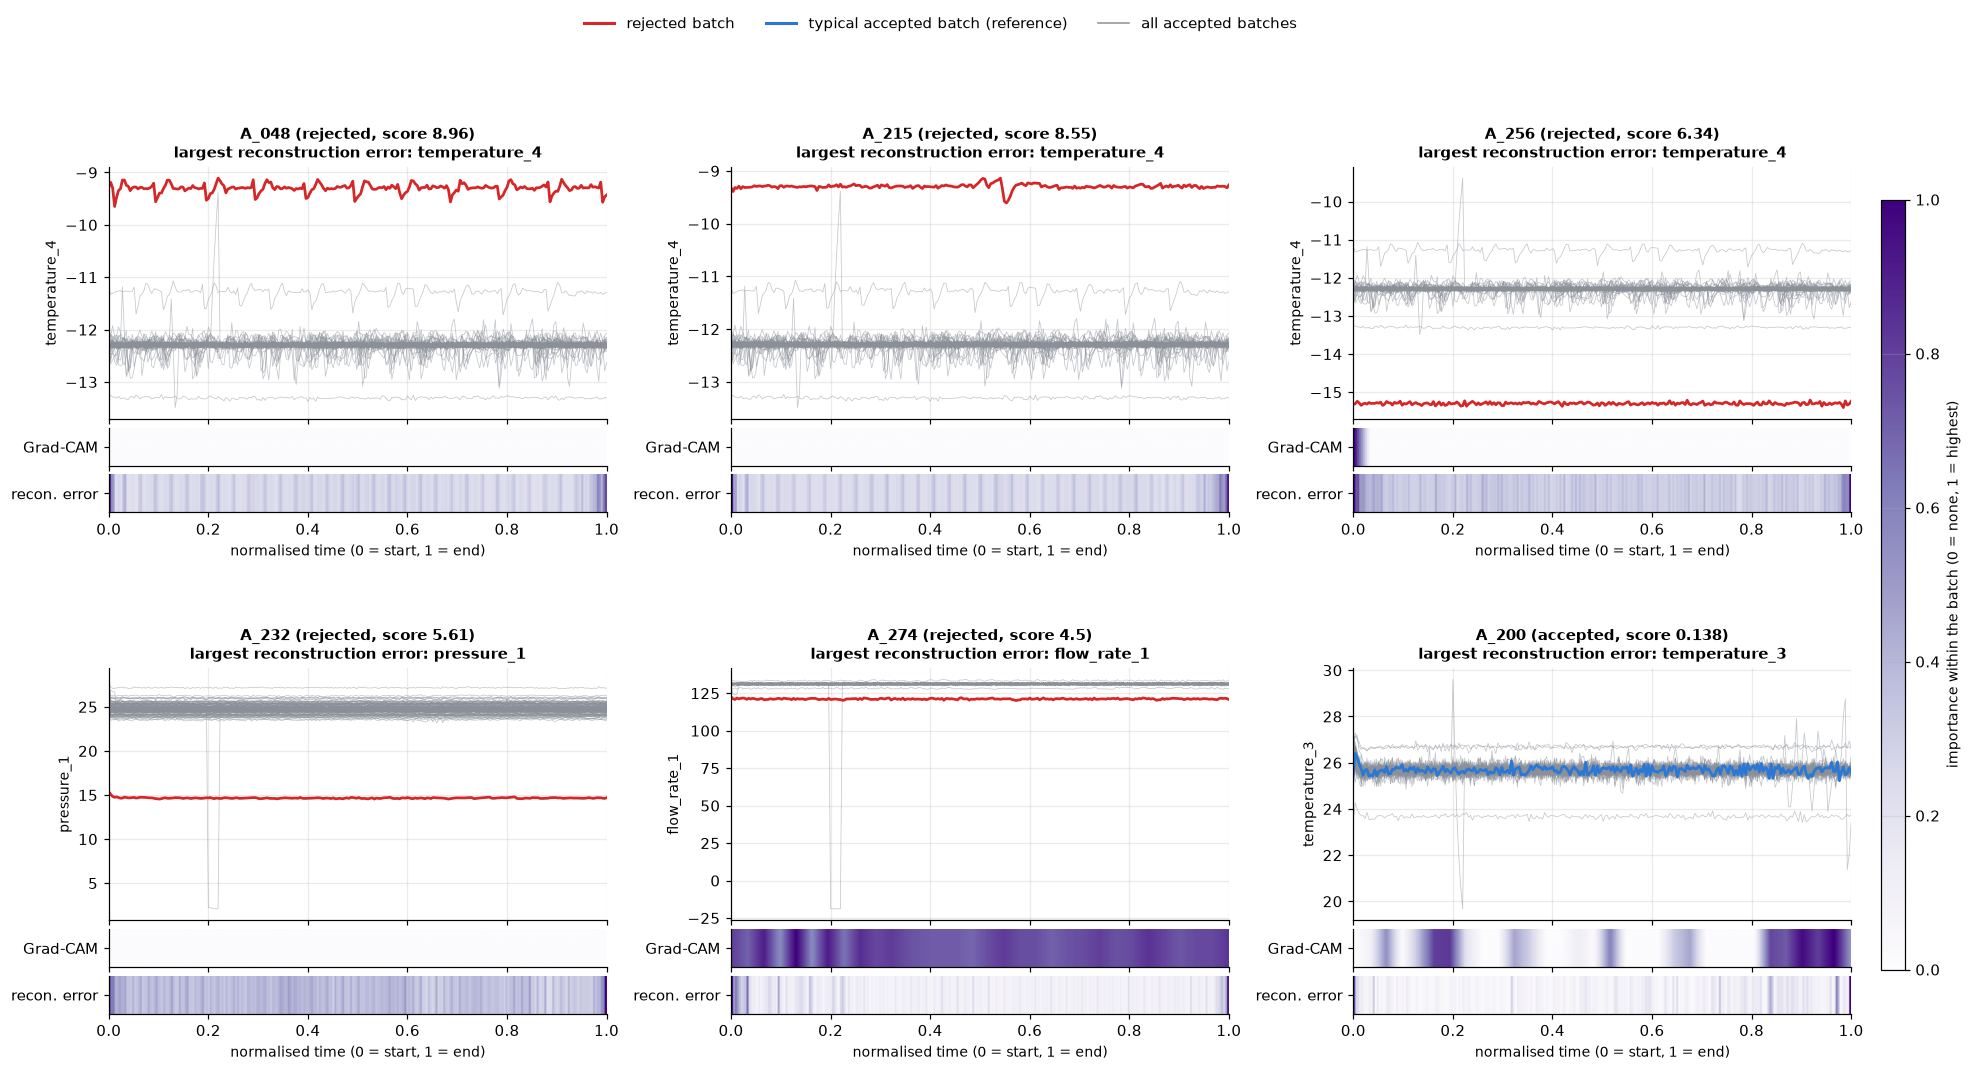

In [6]:
d=D["A"]; r=RES["A"]; rej_i=np.where(~d["acc"])[0]; top5=list(rej_i[np.argsort(-r["score"][rej_i])[:5]])
typ=int(np.argsort(r["score"][d["acc"]])[d["acc"].sum()//2]); acc_i=int(np.where(d["acc"])[0][typ])
fig=plt.figure(figsize=(18,10)); outer=fig.add_gridspec(2,3,left=.05,right=.93,hspace=.45,wspace=.25)
for k,i in enumerate(top5+[acc_i]): explain_block(fig,outer[k//3,k%3],"A",i)
add_colorbar_and_legend(fig); plt.show()

## 5. Conclusions
- **The detector works.** Out-of-fold, the autoencoder catches 5 / 5 rejected batches in process B and 15 / 40 in process A (about the same as the robust score in `anomaly_detection.ipynb`), with ≈ 5 % false alarms. The *shape* channels are essential for B.
- **Grad-CAM fails the sanity check.** In process B it puts essentially none of its weight on the aeration-drop window (see §3.1) and instead highlights the later fed-batch phase; HiResCAM is at chance level. Grad-CAM was designed for classifiers; for an autoencoder, averaging gradients over a whole feature map cancels out a short, local fault, so its heatmap here is **not** a reliable explanation – do not read it as "where the problem is".
- **The reconstruction-error map is the faithful explanation**: ≈ 90 % of its weight lies in the drop window for rejected B batches, and the per-variable error names `aeration_rate` for all five. For process A it highlights the variable with the offset/noise over the whole run, consistent with the EDA (faults that last the whole batch give a spread-out map, which is correct).
- Small training sets (121 / 35 accepted batches) – treat this as an illustration, not a production model.